<a href="https://colab.research.google.com/github/Penn2001/MSSP-607/blob/main/WeeklyModules/Week07/Participation_Activity_Week7_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Participation Activity Week 7 Solution**

Questions and Practice Program:  Complete the following tasks:

1. Use Google Colabs and Python to create a bar chart of yearly sales from the Internet Sales Data Set.

2. Save the active figure to a file in PDF format.

3. Load the code and pdf to the assignment.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%run '/content/drive/MyDrive/Google_connection.py'

Changed directoGit_HUBry to: /content/MSSP-607


In [3]:
%pushd "/content/MSSP-607/data"

/content/MSSP-607/data


['/content/MSSP-607']

In [4]:
import pandas as pd
import numpy as np
import sklearn as sk
from io import StringIO
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
from datetime import date as dt

#set precison of floating point in Pandas
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x) #set precison of floating point in Pandas

In [6]:
#I added an ID Columns to the csv file to identify a key value and used the index_col to set the index for the dataframe.
#You can have Pandas create this column in your dataframe as well.
#See below.
internet_sales = pd.read_csv('InternetSales.csv', parse_dates=['BirthDate','DateFirstPurchase','OrderDate','DueDate','ShipDate'],
                   low_memory=False, encoding='latin-1')
internet_sales

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,2011-01-19,2011-01-31,2011-01-26
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60393,60393,29480,248,London,GB,United Kingdom,AW00029480,NaN,Nina,W,...,13.09,13.09,34.99,2.80,0.87,NaN,NaN,2013-07-17,2013-07-29,2013-07-24
60394,60394,29480,248,London,GB,United Kingdom,AW00029480,NaN,Nina,W,...,6.92,6.92,8.99,0.72,0.22,NaN,NaN,2013-07-17,2013-07-29,2013-07-24
60395,60395,29481,120,Hof,DE,Germany,AW00029481,NaN,Ivan,NaN,...,1898.09,1898.09,3374.99,270.00,84.37,NaN,NaN,2011-08-13,2011-08-25,2011-08-20
60396,60396,29482,179,Saint Ouen,FR,France,AW00029482,NaN,Clayton,NaN,...,1105.81,1105.81,2049.10,163.93,51.23,NaN,NaN,2012-09-18,2012-09-30,2012-09-25


In [7]:
#Reading from a CSV file, we can use the parse_dates option to read dates into datetime datatypes for date manipulations.
#This eliminates the need for explicite data conversions.  Otherwise, dates are read in from a CSV as an object, and
#datetime methods do not operate on objects.  Datetime methods need datetime data types.

#I added and ID Columns to the csv file to identify a key value and used the index_col to set the index for the dataframe.
#You can have Pandas create this column in your dataframe as well.
internet_sales = pd.read_csv('InternetSales.csv', parse_dates=['BirthDate','DateFirstPurchase','OrderDate','DueDate','ShipDate'],
                   low_memory=False, index_col='ID', encoding='latin-1')
internet_sales

,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
ID,,,,,,,,,,,,,,,,,,,,,
0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,2011-01-19,2011-01-31,2011-01-26
1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60393,29480,248,London,GB,United Kingdom,AW00029480,NaN,Nina,W,Raji,...,13.09,13.09,34.99,2.80,0.87,NaN,NaN,2013-07-17,2013-07-29,2013-07-24
60394,29480,248,London,GB,United Kingdom,AW00029480,NaN,Nina,W,Raji,...,6.92,6.92,8.99,0.72,0.22,NaN,NaN,2013-07-17,2013-07-29,2013-07-24
60395,29481,120,Hof,DE,Germany,AW00029481,NaN,Ivan,NaN,Suri,...,1898.09,1898.09,3374.99,270.00,84.37,NaN,NaN,2011-08-13,2011-08-25,2011-08-20


In [8]:
#Notice the datetime type of the OrderDate rather than the object type.

internet_sales['OrderDate']

,OrderDate
ID,
0,2011-01-19
1,2013-01-18
2,2013-01-18
3,2013-05-03
4,2013-05-03
...,...
60393,2013-07-17
60394,2013-07-17
60395,2011-08-13


In [9]:
#Return a dataframe for the graph.  You can use ShipDate as well. I used the dt.year method to select the year portion of the
#datetime datatype. You can select month, day, etc as other options.
#See https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.year.html#pandas.Series.dt.year
yearly_sales = internet_sales.groupby(internet_sales['OrderDate'].dt.year,as_index=True).agg({'SalesAmount': 'sum'})
yearly_sales

,SalesAmount
OrderDate,
2010,43421.04
2011,7075525.93
2012,5842485.20
2013,16351550.34
2014,45694.72


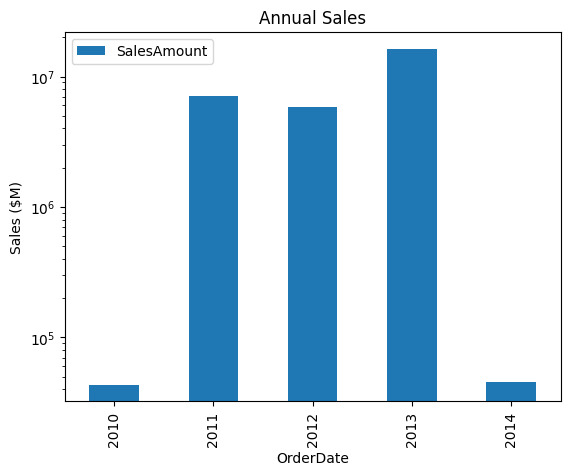

In [12]:
#Using Pandas to plot a bar graph of annual sales
ax=yearly_sales.plot.bar(y='SalesAmount') #One way. Orderdate is the index x and is the default.

#Adding labels
ax.set_ylabel('Sales ($M)')
ax.set_title('Annual Sales')
ax.legend()
ax.set_yscale('log') #Because we need to rescale the Y axis to get 2010 and 2014 to show on the graph, we use 'log' option

In [13]:
#Output the graph to a PDF
ax.figure.savefig ('Internet_Sales.pdf')